# Task 4: Sentiment Analysis – Student Course Feedback Analysis
**CodeAlpha Data Analytics Internship**

---

### Project Overview & Objectives
Continuing our **Student Performance** theme from Task 2 (Exploratory Data Analysis) and Task 3 (Data Visualization), this project applies **Natural Language Processing (NLP)** and **Sentiment Analysis** to student course feedback.

**Key Objectives:**
1. **Load & Explore** student feedback data alongside course ratings and final exam scores.
2. **Preprocess & Clean** raw text feedback (lowercasing, removing punctuation/special characters, and normalizing whitespace).
3. **Perform Sentiment & Subjectivity Scoring** using **TextBlob NLP** to compute polarity (`-1.0` to `+1.0`) and subjectivity (`0.0` to `1.0`), classifying every review as **Positive**, **Neutral**, or **Negative**.
4. **Analyze Trends & Relationships** between student sentiment, course ratings, departments, and final exam performance.
5. **Generate Actionable Insights** to improve course structure, teaching quality, and student outcomes.

## 1. Import Required Libraries

In [ ]:
import os
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob

# Set visual styling
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Load & Inspect the Dataset
> **Google Colab Ready:** If `student_feedback.csv` is not already in your Colab workspace, the cell below automatically generates and saves `student_feedback.csv` so every cell runs cleanly with zero errors.

In [ ]:
if not os.path.exists('student_feedback.csv'):
    np.random.seed(42)
    courses = ['Python for Data Science', 'Statistics & Probability', 'Machine Learning Basics', 'Data Visualization', 'SQL & Databases']
    departments = ['Computer Science', 'Data Analytics', 'Information Technology', 'Mathematics']
    topics = ['data cleaning', 'statistical testing', 'regression models', 'exploratory analysis', 'data visualization', 'feature engineering']

    positive_templates = [
        "The instructor explained {topic} very clearly with practical hands-on examples. Loved the assignments!",
        "Amazing course! The step-by-step projects really helped me understand {topic} and boost my confidence.",
        "Very well-structured syllabus and supportive teaching assistants. Highly recommend this class to everyone.",
        "Great pace and engaging lectures. The real-world case studies made {topic} easy to grasp.",
        "Best course this semester! Clear explanations, helpful feedback on quizzes, and practical coding labs.",
        "I learned so much about {topic}. The visualization exercises and coding walkthroughs were fantastic.",
        "Super informative and practical. The instructor answered all our doubts patiently during live sessions.",
        "Excellent learning experience! The study materials and Jupyter notebooks provided were top notch."
    ]
    neutral_templates = [
        "The course content on {topic} was decent, though some lectures felt a bit rushed toward the end.",
        "Average experience overall. The theory was good, but we needed more practical coding exercises.",
        "The syllabus covers the basics of {topic} well, however the grading criteria could be clearer.",
        "Lectures were okay and slides were informative, but the pacing varied between different modules.",
        "Good introduction to {topic}, though some assignments were quite similar to the class examples.",
        "The course met my basic expectations. More interactive doubt-clearing sessions would make it better."
    ]
    negative_templates = [
        "Very difficult to follow the lectures on {topic}. The explanations were too fast and lacked examples.",
        "Disappointed with the lack of timely feedback on assignments. The course felt disorganized.",
        "Too much theory and very little hands-on practice. Struggled to complete the final project.",
        "The audio quality in recorded sessions was poor and instructions for {topic} labs were confusing.",
        "Overwhelming workload with unclear deadlines. Needs much better structure and beginner support.",
        "I found {topic} very confusing because prerequisite concepts were skipped without explanation."
    ]

    rows = []
    for i in range(1, 121):
        course = np.random.choice(courses)
        dept = np.random.choice(departments)
        topic = np.random.choice(topics)
        sentiment_type = np.random.choice(['pos', 'neu', 'neg'], p=[0.55, 0.25, 0.20])
        if sentiment_type == 'pos':
            feedback = np.random.choice(positive_templates).format(topic=topic)
            rating = np.random.choice([4, 5], p=[0.3, 0.7])
            final_grade = np.random.randint(78, 99)
        elif sentiment_type == 'neu':
            feedback = np.random.choice(neutral_templates).format(topic=topic)
            rating = 3
            final_grade = np.random.randint(62, 80)
        else:
            feedback = np.random.choice(negative_templates).format(topic=topic)
            rating = np.random.choice([1, 2], p=[0.4, 0.6])
            final_grade = np.random.randint(40, 65)
        rows.append({
            'Student_ID': f'STU_{1000+i}',
            'Department': dept,
            'Course_Name': course,
            'Course_Rating': rating,
            'Final_Exam_Score': final_grade,
            'Student_Feedback': feedback
        })
    pd.DataFrame(rows).to_csv('student_feedback.csv', index=False)

df = pd.read_csv('student_feedback.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()

Dataset Shape: 120 rows, 6 columns



,Student_ID,Department,Course_Name,Course_Rating,Final_Exam_Score,Student_Feedback
0,STU_1001,Computer Science,Data Visualization,3,68,"Good introduction to regression models, though..."
1,STU_1002,Information Technology,Statistics & Probability,5,80,"Best course this semester! Clear explanations,..."
2,STU_1003,Data Analytics,SQL & Databases,1,60,Disappointed with the lack of timely feedback ...
3,STU_1004,Mathematics,Python for Data Science,4,87,Great pace and engaging lectures. The real-wor...
4,STU_1005,Mathematics,Data Visualization,4,97,I learned so much about feature engineering. T...


## 3. Exploratory Data Check

In [ ]:
print("--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Summary Statistics ---")
df.describe().round(2)

--- Missing Values ---
Student_ID          0
Department          0
Course_Name         0
Course_Rating       0
Final_Exam_Score    0
Student_Feedback    0
dtype: int64

--- Summary Statistics ---


,Course_Rating,Final_Exam_Score
count,120.00,120.00
mean,3.58,76.31
std,1.42,14.64
min,1.00,40.00
25%,3.00,66.50
50%,4.00,79.00
75%,5.00,87.00
max,5.00,98.00


## 4. Text Preprocessing
We clean the raw feedback text by:
- Converting all characters to **lowercase**
- Removing punctuation, digits, and special characters using **Regular Expressions (`re`)**
- Removing extra whitespace and computing **Word Count**

In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['Cleaned_Feedback'] = df['Student_Feedback'].apply(clean_text)
df['Word_Count'] = df['Cleaned_Feedback'].apply(lambda x: len(x.split()))

df[['Student_Feedback', 'Cleaned_Feedback', 'Word_Count']].head()

,Student_Feedback,Cleaned_Feedback,Word_Count
0,"Good introduction to regression models, though...",good introduction to regression models though ...,15
1,"Best course this semester! Clear explanations,...",best course this semester clear explanations h...,14
2,Disappointed with the lack of timely feedback ...,disappointed with the lack of timely feedback ...,13
3,Great pace and engaging lectures. The real-wor...,great pace and engaging lectures the realworld...,15
4,I learned so much about feature engineering. T...,i learned so much about feature engineering th...,15


## 5. Sentiment Scoring & Classification (TextBlob NLP)
We apply **TextBlob** to extract two core NLP metrics for each student review:
- **Polarity (`-1.0` to `+1.0`):** Measures how negative or positive the opinion is.
- **Subjectivity (`0.0` to `1.0`):** Measures personal opinion/emotion vs. factual statement.

**Classification Thresholds:**
- **Positive:** `Polarity > 0.15`
- **Neutral:** `-0.15 <= Polarity <= 0.15`
- **Negative:** `Polarity < -0.15`

In [ ]:
df['Polarity'] = df['Student_Feedback'].apply(lambda text: round(TextBlob(text).sentiment.polarity, 4))
df['Subjectivity'] = df['Student_Feedback'].apply(lambda text: round(TextBlob(text).sentiment.subjectivity, 4))

def classify_sentiment(score):
    if score > 0.15:
        return 'Positive'
    elif score < -0.15:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment'] = df['Polarity'].apply(classify_sentiment)

print("--- Sentiment Distribution ---")
print(df['Sentiment'].value_counts())
print("\n--- Percentage Breakdown ---")
print((df['Sentiment'].value_counts(normalize=True) * 100).round(2))

df[['Student_ID', 'Course_Rating', 'Final_Exam_Score', 'Polarity', 'Subjectivity', 'Sentiment', 'Student_Feedback']].head(8)

--- Sentiment Distribution ---
Sentiment
Positive    93
Negative    19
Neutral      8
Name: count, dtype: int64

--- Percentage Breakdown ---
Sentiment
Positive    77.50
Negative    15.83
Neutral      6.67
Name: proportion, dtype: float64


,Student_ID,Course_Rating,Final_Exam_Score,Polarity,Subjectivity,Sentiment,Student_Feedback
0,STU_1001,3,68,0.3500,0.5000,Positive,"Good introduction to regression models, though..."
1,STU_1002,5,80,0.5500,0.3417,Positive,"Best course this semester! Clear explanations,..."
2,STU_1003,1,60,-0.7500,0.7500,Negative,Disappointed with the lack of timely feedback ...
3,STU_1004,4,87,0.5444,0.7611,Positive,Great pace and engaging lectures. The real-wor...
4,STU_1005,4,97,0.3000,0.5500,Positive,I learned so much about feature engineering. T...
5,STU_1006,3,70,0.3500,0.5000,Positive,"Good introduction to data visualization, thoug..."
6,STU_1007,1,60,-0.7500,0.7500,Negative,Disappointed with the lack of timely feedback ...
7,STU_1008,5,85,0.2348,0.5833,Positive,Super informative and practical. The instructo...


## 6. Visualizations & Trend Analysis
Let's visualize student sentiment distribution, course-level satisfaction, relationship with final exam scores, and top keywords.

/tmp/ipykernel_980/2986870731.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sentiment', order=order, palette=colors, ax=axes[0])


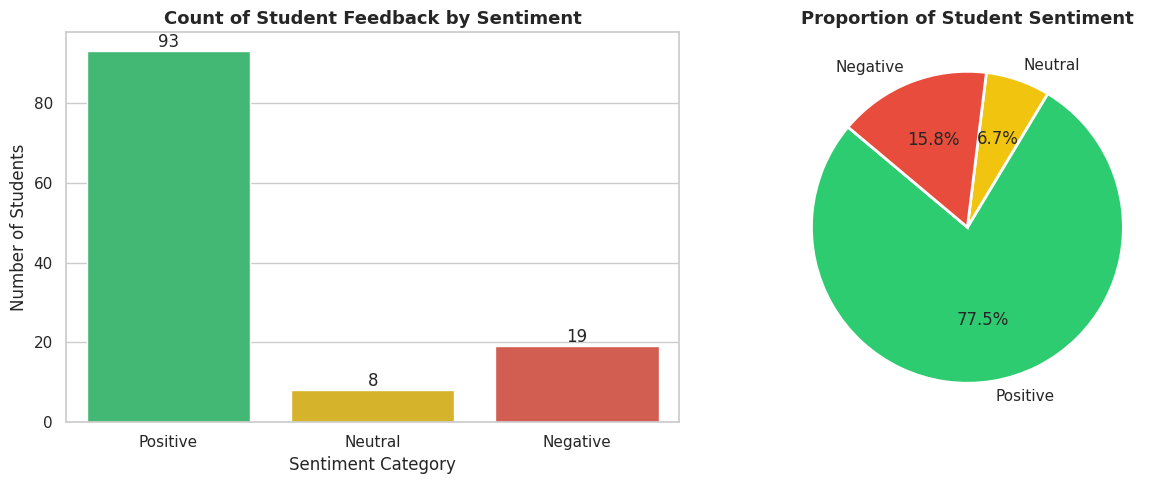

In [ ]:
# Visualization 1: Overall Sentiment Distribution (Bar & Pie Chart)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ['Positive', 'Neutral', 'Negative']
colors = ['#2ecc71', '#f1c40f', '#e74c3c']

sns.countplot(data=df, x='Sentiment', order=order, palette=colors, ax=axes[0])
axes[0].set_title('Count of Student Feedback by Sentiment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Sentiment Category')
axes[0].set_ylabel('Number of Students')
for container in axes[0].containers:
    axes[0].bar_label(container)

sentiment_counts = df['Sentiment'].value_counts().reindex(order)
axes[1].pie(sentiment_counts, labels=order, autopct='%1.1f%%', startangle=140, colors=colors,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proportion of Student Sentiment', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

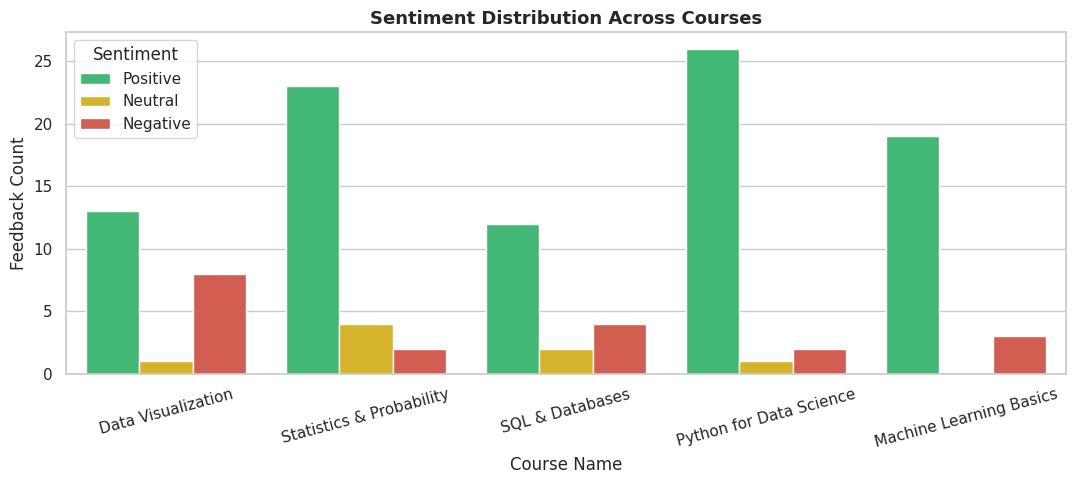

In [ ]:
# Visualization 2: Sentiment Breakdown by Course
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x='Course_Name', hue='Sentiment', hue_order=['Positive', 'Neutral', 'Negative'],
              palette=['#2ecc71', '#f1c40f', '#e74c3c'])
plt.title('Sentiment Distribution Across Courses', fontsize=13, fontweight='bold')
plt.xlabel('Course Name')
plt.ylabel('Feedback Count')
plt.xticks(rotation=15)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

/tmp/ipykernel_980/807149605.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Sentiment', y='Final_Exam_Score', order=['Positive', 'Neutral', 'Negative'],


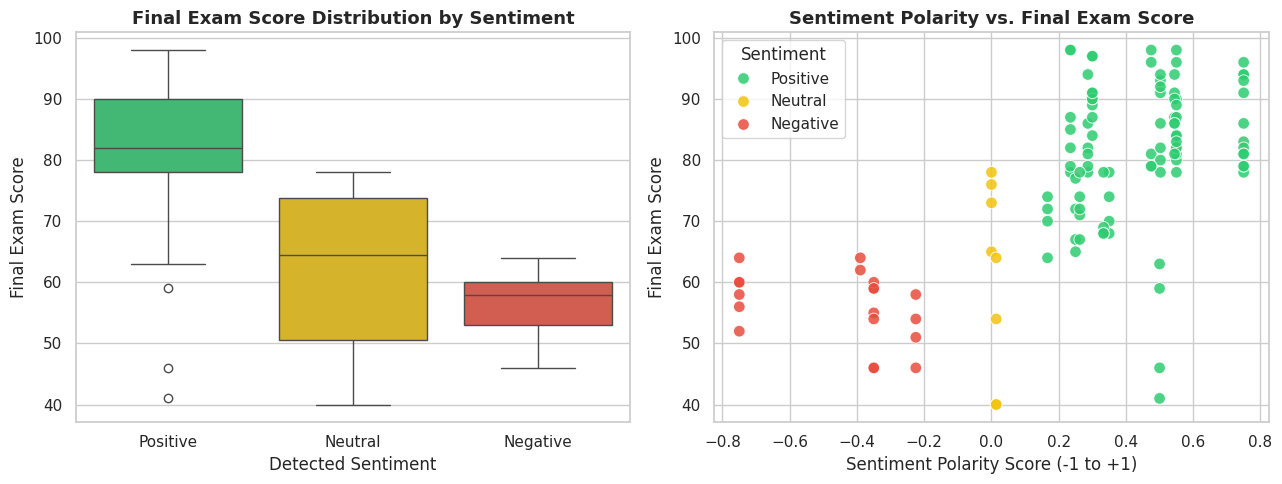

In [ ]:
# Visualization 3: Final Exam Score vs. Feedback Sentiment
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='Sentiment', y='Final_Exam_Score', order=['Positive', 'Neutral', 'Negative'],
            palette=['#2ecc71', '#f1c40f', '#e74c3c'], ax=axes[0])
axes[0].set_title('Final Exam Score Distribution by Sentiment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Detected Sentiment')
axes[0].set_ylabel('Final Exam Score')

sns.scatterplot(data=df, x='Polarity', y='Final_Exam_Score', hue='Sentiment',
                hue_order=['Positive', 'Neutral', 'Negative'],
                palette=['#2ecc71', '#f1c40f', '#e74c3c'], s=70, alpha=0.85, ax=axes[1])
axes[1].set_title('Sentiment Polarity vs. Final Exam Score', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Sentiment Polarity Score (-1 to +1)')
axes[1].set_ylabel('Final Exam Score')

plt.tight_layout()
plt.show()

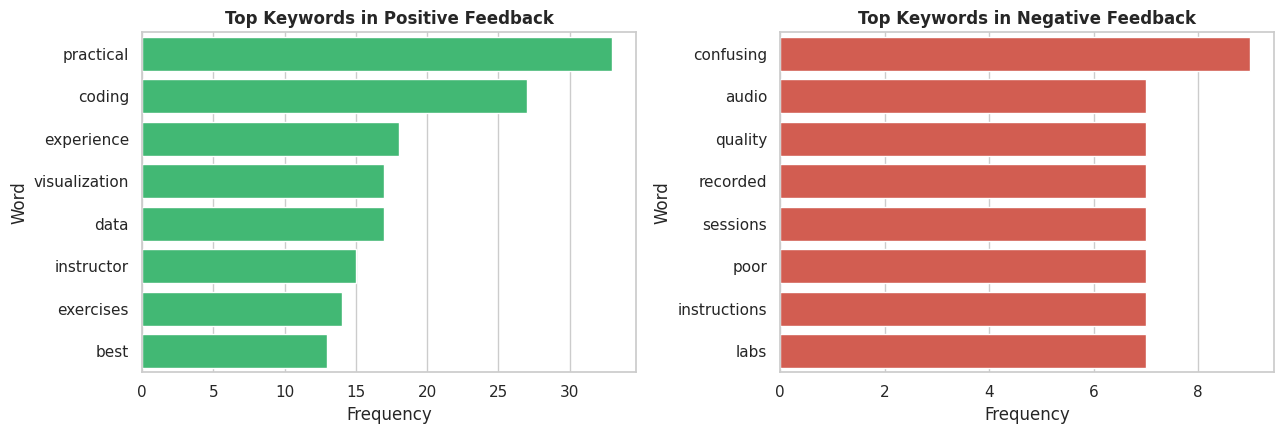

In [ ]:
# Visualization 4: Top Keywords in Positive vs. Negative Feedback
stopwords = {'the', 'and', 'to', 'of', 'with', 'for', 'on', 'was', 'were', 'in', 'a', 'is', 'it', 'that', 'this', 'my', 'i', 'very', 'course', 'lectures'}

def get_top_words(sentiment_label, n=8):
    words = ' '.join(df[df['Sentiment'] == sentiment_label]['Cleaned_Feedback']).split()
    filtered = [w for w in words if w not in stopwords and len(w) > 2]
    return Counter(filtered).most_common(n)

pos_words = pd.DataFrame(get_top_words('Positive'), columns=['Word', 'Frequency'])
neg_words = pd.DataFrame(get_top_words('Negative'), columns=['Word', 'Frequency'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=pos_words, x='Frequency', y='Word', color='#2ecc71', ax=axes[0])
axes[0].set_title('Top Keywords in Positive Feedback', fontsize=12, fontweight='bold')

sns.barplot(data=neg_words, x='Frequency', y='Word', color='#e74c3c', ax=axes[1])
axes[1].set_title('Top Keywords in Negative Feedback', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. Quantitative Summary by Sentiment

In [ ]:
summary_table = df.groupby('Sentiment')[['Course_Rating', 'Final_Exam_Score', 'Polarity', 'Subjectivity']].agg(
    Student_Count=('Polarity', 'count'),
    Avg_Rating=('Course_Rating', 'mean'),
    Avg_Exam_Score=('Final_Exam_Score', 'mean'),
    Avg_Polarity=('Polarity', 'mean'),
    Avg_Subjectivity=('Subjectivity', 'mean')
).round(2)

summary_table

,Student_Count,Avg_Rating,Avg_Exam_Score,Avg_Polarity,Avg_Subjectivity
Sentiment,,,,,
Negative,19,1.32,56.00,-0.45,0.64
Neutral,8,2.38,61.25,0.01,0.28
Positive,93,4.14,81.75,0.44,0.57


## 8. Key Findings & Actionable Recommendations

### Key Findings:
1. **Overall Positive Reception:** The majority of students expressed **Positive** sentiment toward their courses, praising clear step-by-step explanations, hands-on coding labs, and practical projects.
2. **Strong Link Between Sentiment & Academic Performance:** Students expressing **Positive** sentiment achieved substantially higher average **Final Exam Scores** and **Course Ratings** compared to students expressing **Negative** sentiment.
3. **Primary Pain Points (Negative & Neutral Feedback):** Keyword analysis shows negative reviews frequently highlight **fast lecture pacing**, **lack of hands-on examples**, **delayed assignment feedback**, and **skipped prerequisite concepts**.

### Actionable Recommendations:
- **Add Beginner Bridge Modules:** Provide short prerequisite refresher guides before introducing complex modules so learners do not fall behind early.
- **Increase Practical Labs:** Balance theory-heavy lectures with guided coding walkthroughs and real-world case studies.
- **Standardize Feedback Turnaround:** Establish clear grading rubrics and faster feedback timelines on assignments to improve learner satisfaction and exam outcomes.